# Lista 4
Zuzanna Sosnowska

In [145]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import pandas as pd

### Zadanie 1

**Wstęp do drzew decyzyjnych**: Wczytaj zbiór danych `Iris` i zwizualizuj go. Zbuduj model drzewa decyzyjnego, używając klasy `DecisionTreeClassifier` z biblioteki `scikit-learn`. Przedstaw strukturę drzewa na wykresie za pomocą funkcji `plot tree` lub `export graphviz` i zinterpretuj warunki podziału.

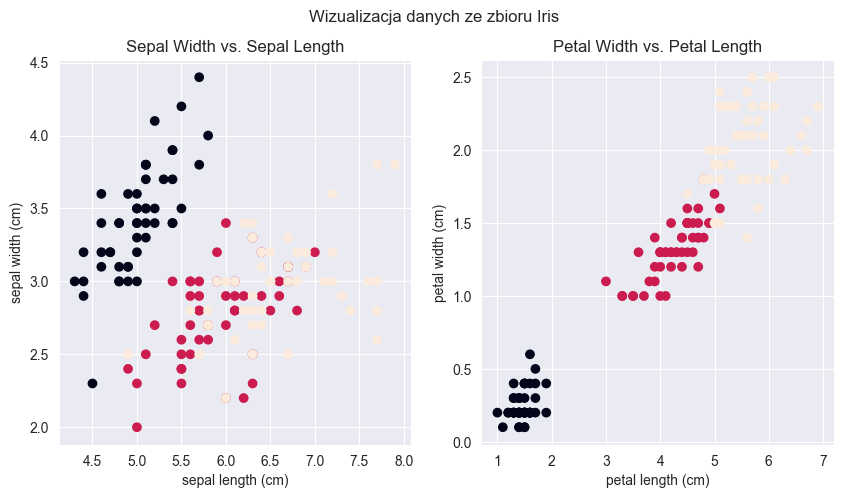

In [146]:
df = load_iris(as_frame=True).frame

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('Wizualizacja danych ze zbioru Iris')

ax1.scatter(df["sepal length (cm)"], df["sepal width (cm)"], c=df["target"])
ax1.set_xlabel('sepal length (cm)')
ax1.set_ylabel('sepal width (cm)')
ax1.set_title('Sepal Width vs. Sepal Length')
ax2.scatter(df["petal length (cm)"], df["petal width (cm)"], c=df["target"])
ax2.set_xlabel('petal length (cm)')
ax2.set_ylabel('petal width (cm)')
ax2.set_title('Petal Width vs. Petal Length')

plt.show()

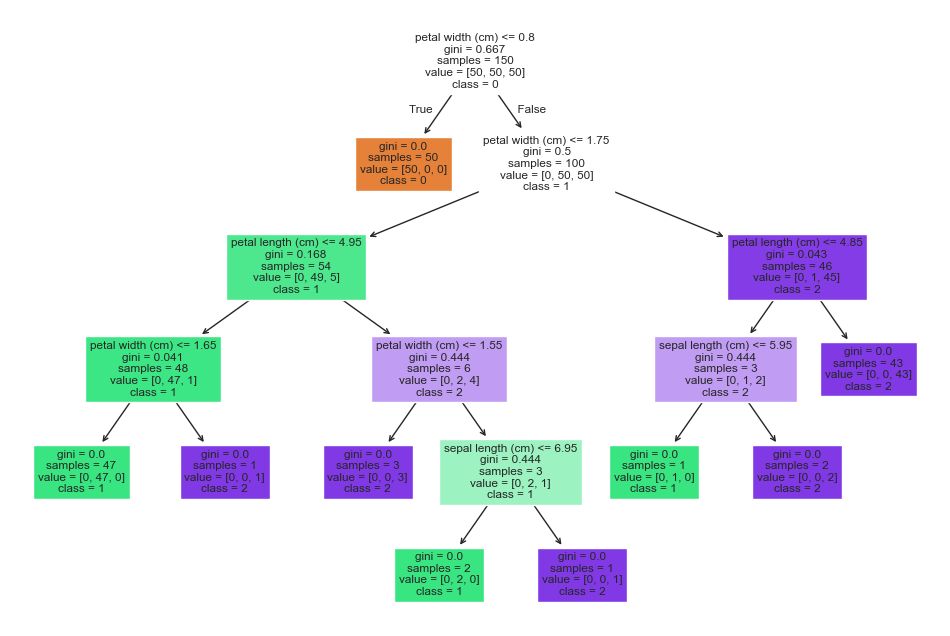

In [147]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz


y = df["target"]
X = df.drop("target", axis=1)

clf = DecisionTreeClassifier()
clf = clf.fit(X=X, y=y)

plt.figure(figsize=(12, 8))
plot_tree(clf, feature_names=X.columns, class_names=[str(c) for c in clf.classes_], filled=True)
plt.show()

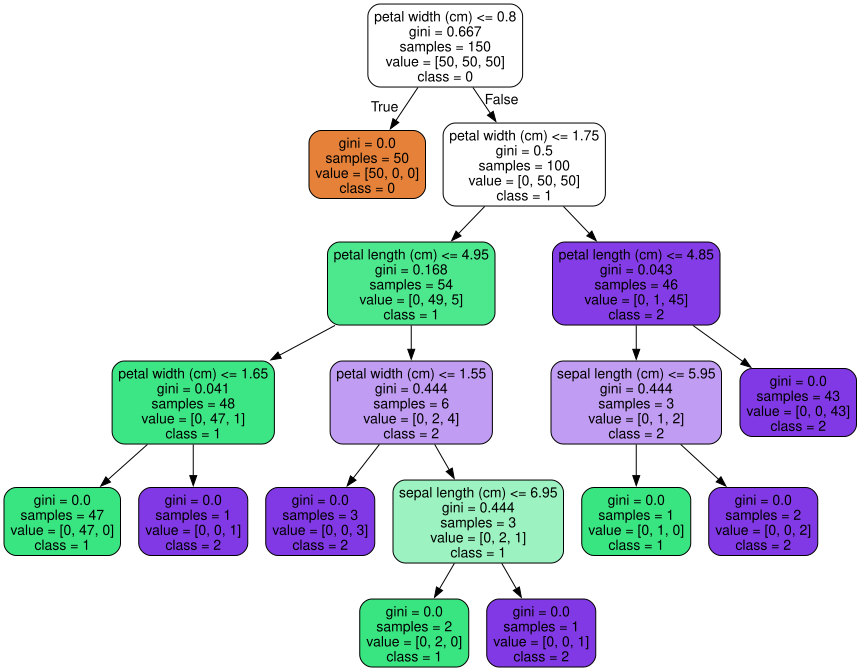

In [148]:
import graphviz

dot_data = export_graphviz(
    clf,
    out_file=None,
    feature_names=X.columns,
    class_names=[str(c) for c in clf.classes_],
    filled=True,
    rounded=True
)

graph = graphviz.Source(dot_data)
graph

Drzewo decyzyjne to model, który klasyfikuje dane, dzieląc je stopniowo na coraz bardziej jednorodne grupy. Działa w bardzo intuicyjny sposób: na każdym etapie wybiera jedną zmienną (cechę), która najlepiej rozróżnia obserwowane klasy. Ustala dla niej pewien próg podziału i dzieli dane na dwie gałęzie — jedną spełniającą warunek, a drugą niespełniającą. Proces ten powtarza się w każdej gałęzi, aż do uzyskania grup, w których wszystkie elementy należą do jednej klasy lub dalszy podział nie poprawia jakości modelu.

W analizowanym modelu pierwszy podział został dokonany na podstawie szerokości płatka. Wartość `petal_width ≤ 0.8` natychmiast oddziela wszystkie próbki jednego gatunku, tworząc czysty liść drzewa. Pozostałe gatunki są rozróżniane kolejnymi podziałami opartymi głównie na długości i szerokości płatka. Drzewo stopniowo wydziela małe, coraz bardziej jednorodne grupy, aż do momentu, w którym każdy węzeł końcowy zawiera praktycznie wyłącznie jedną klasę. Dzięki temu powstaje czytelny zestaw reguł pozwalających skutecznie odróżnić trzy gatunki.

### Zadanie 2

**Problem przeuczenia (overfitting)**: Wytrenuj dwa modele drzewa decyzyjnego na danych `Iris`: jeden bez ograniczeń (domyślne parametry) i drugi z ograniczoną maksymalną głębokością (`max depth`). Porównaj ich dokładność na zbiorze treningowym i testowym. Wyjaśnij zjawisko przeuczenia.

In [151]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [153]:
dtc_model = DecisionTreeClassifier()
dtc_model.fit(X=X_train, y=y_train)

dtc_model_max_depth = DecisionTreeClassifier(max_depth=3)
dtc_model_max_depth.fit(X=X_train, y=y_train)

y_pred1 = dtc_model.predict(X_test)
y_pred2 = dtc_model_max_depth.predict(X_test)

score1 = dtc_model.score(X=X_test, y=y_test)
score2 = dtc_model_max_depth.score(X=X_test, y=y_test)

score1_train = dtc_model.score(X=X_train, y=y_train)
score2_train = dtc_model_max_depth.score(X=X_train, y=y_train)

pd.DataFrame({"DecisionTreeClassifier bez ograniczeń": [score1, score1_train],
              "DecisionTreeClassifier z max depth = 3": [score2, score2_train]},
             index=["zbiór testowy", "zbiór treningowy"])

,DecisionTreeClassifier bez ograniczeń,DecisionTreeClassifier z max depth = 3
zbiór testowy,0.911111,0.977778
zbiór treningowy,1.000000,0.980952


In [154]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score


print("Macierz pomyłek dla modelu bez ograniczeń:")
print(confusion_matrix(y_test, y_pred1))

print("Macierz pomyłek dla modelu z maksymalnym zagłębieniem = 3:")
print(confusion_matrix(y_test, y_pred2))

accuracy1 =  accuracy_score(y_test, y_pred1)
precision1 = precision_score(y_test, y_pred1, average='macro')
recall1 =  recall_score(y_test, y_pred1, average='macro')

accuracy2 = accuracy_score(y_test, y_pred2)
precision2 = precision_score(y_test, y_pred2, average='macro')
recall2 = recall_score(y_test, y_pred2, average='macro')

pd.DataFrame({"DecisionTreeClassifier bez ograniczeń": [accuracy1, precision1, recall1],
              "DecisionTreeClassifier z max depth = 3": [accuracy2, precision2, recall2]},
             index=["Accuracy", "Precision", "Recall"])

Macierz pomyłek dla modelu bez ograniczeń:
[[15  0  0]
 [ 0 13  2]
 [ 0  2 13]]
Macierz pomyłek dla modelu z maksymalnym zagłębieniem = 3:
[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]


,DecisionTreeClassifier bez ograniczeń,DecisionTreeClassifier z max depth = 3
Accuracy,0.911111,0.977778
Precision,0.911111,0.979167
Recall,0.911111,0.977778


W porównaniu dwóch modeli widać, że drzewo bez ograniczeń dopasowało się do danych treningowych idealnie (100%). Model z ograniczoną głębokością ma minimalnie gorszy wynik na danych treningowych, ale na danych testowych osiąga lepszy wynik.

Potwierdzają to również metryki `accuracy`, `precision` i `recall` - dla modelu z ograniczonym zagłębieniem osiągają wyższe wartości na zbiorze testowym niż dla modelu bez ograniczeń.

### Zadanie 3

**Lasy losowe (Random Forest)**: Zbuduj model lasu losowego, używając klasy `RandomForestClassifier`. Porównaj jego dokładność i stabilność z modelem pojedynczego drzewa decyzyjnego. Wyjaśnij, w jaki sposób losowość wpływa na poprawę wyników.

In [159]:
from sklearn.ensemble import RandomForestClassifier


rfc_model = RandomForestClassifier()
rfc_model.fit(X=X_train, y=y_train)
rfc_score = rfc_model.score(X=X_test, y=y_test)
rfc_score_train = rfc_model.score(X=X_train, y=y_train)

pd.DataFrame({"DecisionTreeClassifier bez ograniczeń": [score1, score1_train],
              "DecisionTreeClassifier z max depth = 4": [score2, score2_train],
              "RandomForestClassifier": [rfc_score, rfc_score_train]},
             index=["Score - zbiór testowy", "Score - zbiór treningowy"])

,DecisionTreeClassifier bez ograniczeń,DecisionTreeClassifier z max depth = 4,RandomForestClassifier
Score - zbiór testowy,0.911111,0.977778,0.888889
Score - zbiór treningowy,1.000000,0.980952,1.000000


In [158]:
from sklearn.datasets import load_breast_cancer


breast_cancer_df = load_breast_cancer(as_frame=True).frame

train_X, test_X, train_y, test_y = train_test_split(breast_cancer_df.drop('target', axis=1), breast_cancer_df['target'], test_size=0.3)

model_1 = DecisionTreeClassifier()
model_2 = RandomForestClassifier()

model_1.fit(train_X, train_y)
model_2.fit(train_X, train_y)

y_pred1 = model_1.predict(test_X)
y_pred2 = model_2.predict(test_X)

pd.DataFrame({"DecisionTreeClassifier": [accuracy_score(test_y, y_pred1),
                                         precision_score(test_y, y_pred1, average='macro'),
                                         recall_score(test_y, y_pred1, average='macro')],
              "RandomForestClassifier": [accuracy_score(test_y, y_pred2),
                                         precision_score(test_y, y_pred2, average='macro'),
                                         recall_score(test_y, y_pred2, average='macro')]},
             index=["Accuracy", "Precision", "Recall"])

,DecisionTreeClassifier,RandomForestClassifier
Accuracy,0.929825,0.953216
Precision,0.926802,0.956210
Recall,0.920613,0.942439


Random Forest buduje wiele drzew, spośród których każde uczy się na trochę innych danych (bootstrap) i używa tylko losowej części cech przy każdym podziale (feature subsampling).
Dwa rodzaje losowości sprawiają, że każde drzewo jest nieco inne. Dzięki temu model końcowy jest bardziej „wyrównany” — pojedyncze błędne podziały lub przeuczenie jednego drzewa zostają zniwelowane przez pozostałe.
W efekcie las losowy zwykle generalizuje lepiej i jest bardziej stabilny niż pojedyncze drzewo.

### Zadanie 4

**Znaczenie cech (Feature Importance):** Dla wytrenowanego modelu lasu losowego, uzyskaj informację o ważności poszczególnych cech. Zwizualizuj ważność cech na wykresie słupkowym i zinterpretuj, które zmienne mają największy wpływ na klasyfikację.

[0.11072937 0.02597434 0.39753865 0.46575765]


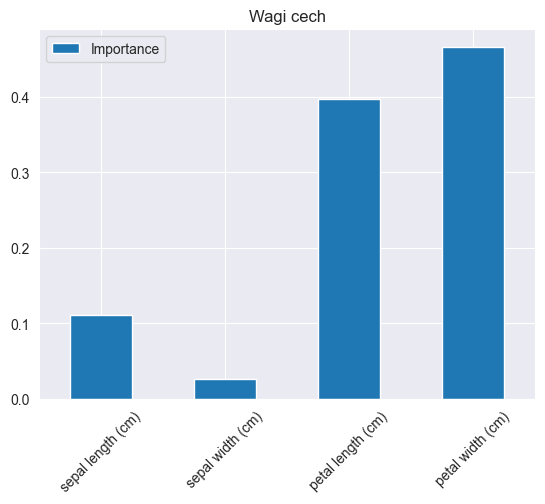

In [160]:
pd.DataFrame(rfc_model.feature_importances_, columns=["Importance"], index=X.columns).plot(kind='bar', rot=45, title="Wagi cech")
print(rfc_model.feature_importances_)

W przypadku zbioru danych Iris największy wpływ na klasyfikację mają cechy `petal length` i `petal width`.

[0.03121461 0.01559587 0.06451518 0.05769427 0.00507055 0.01406491
 0.03280777 0.10625456 0.00309768 0.00373878 0.01260338 0.00318645
 0.00647609 0.02687629 0.00498978 0.00285434 0.00580653 0.00457855
 0.00572073 0.00326815 0.11166534 0.01309537 0.15792566 0.06272971
 0.00980516 0.0126359  0.03625984 0.170846   0.00944667 0.00517587]


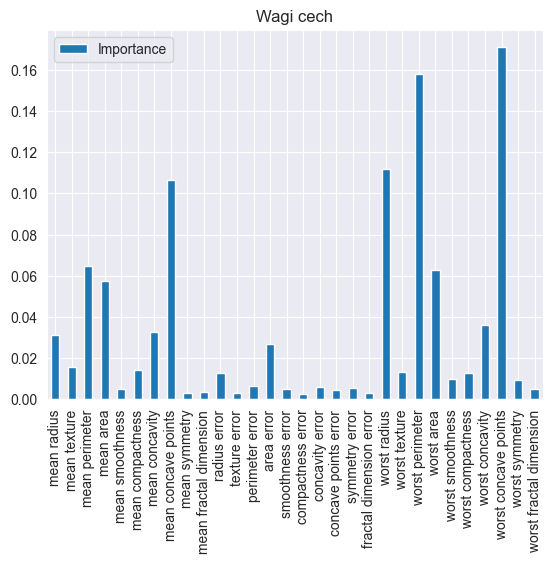

In [76]:
pd.DataFrame(model_2.feature_importances_, columns=["Importance"], index=test_X.columns).plot(kind='bar', rot=90, title="Wagi cech")
print(model_2.feature_importances_)

### Zadanie 5

**Zastosowanie AdaBoost:** Użyj klasy `AdaBoostClassifier` z biblioteki `scikit-learn`. Wytrenuj model z różną liczbą estymatorów (`n estimators`) i przeanalizuj, jak wpływa to na wydajność.

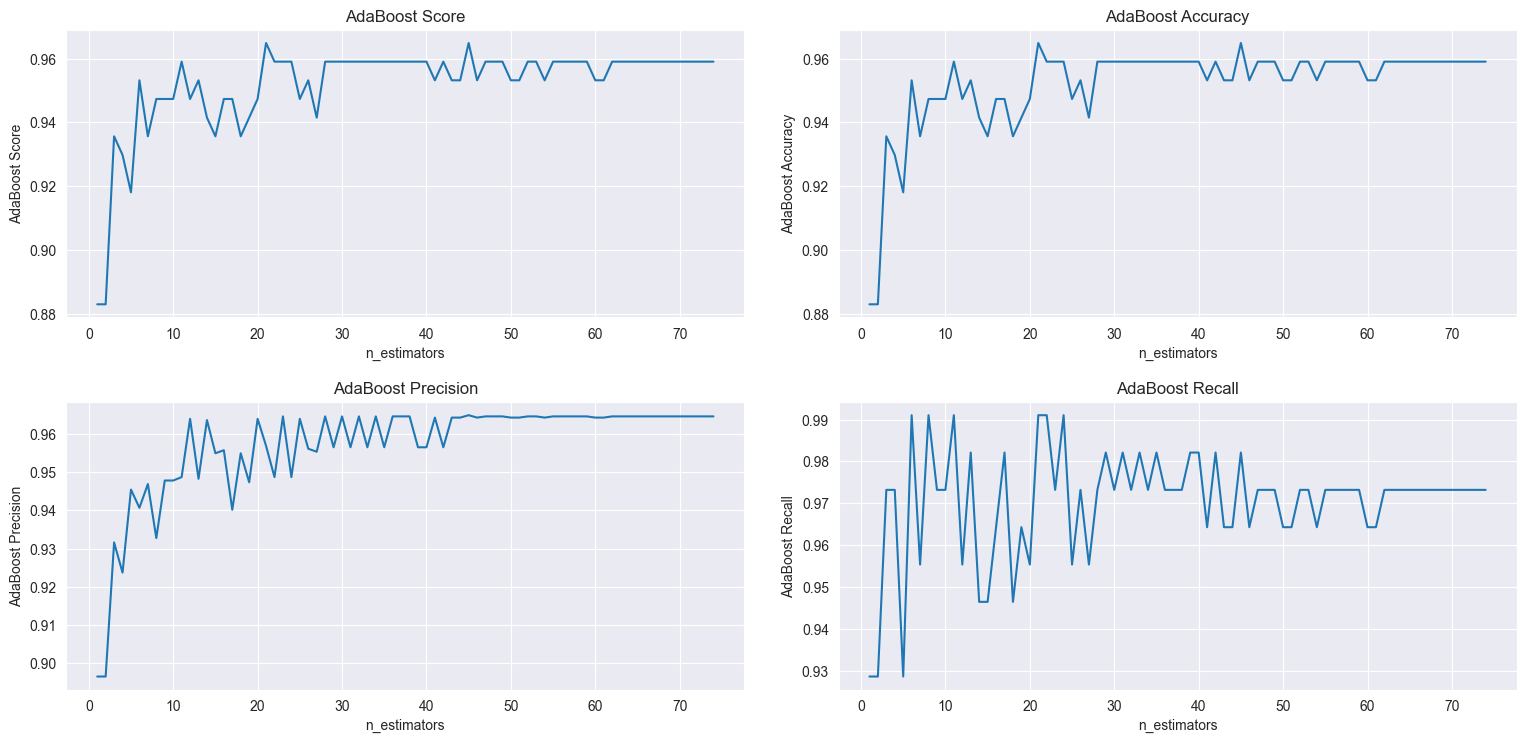

In [100]:
from sklearn.ensemble import AdaBoostClassifier


abc_scores = []
abc_accuracies = []
abc_precisions = []
abc_recalls = []
n_estimators = [i for i in range(1, 75)]

for n in n_estimators:
    abc_model = AdaBoostClassifier(n_estimators=n)
    abc_model.fit(X=train_X, y=train_y)
    abc_scores.append(abc_model.score(X=test_X, y=test_y))
    abc_accuracies.append(accuracy_score(test_y, abc_model.predict(test_X)))
    abc_precisions.append(precision_score(test_y, abc_model.predict(test_X)))
    abc_recalls.append(recall_score(test_y, abc_model.predict(test_X)))


fig, ax = plt.subplots(2, 2, figsize=(16, 8))
fig.tight_layout(pad=4)

ax[0, 0].plot(n_estimators, abc_scores)
ax[0, 0].set_title('AdaBoost Score')
ax[0, 0].set_xlabel('n_estimators')
ax[0, 0].set_ylabel('AdaBoost Score')

ax[0, 1].plot(n_estimators, abc_accuracies)
ax[0, 1].set_title('AdaBoost Accuracy')
ax[0, 1].set_xlabel('n_estimators')
ax[0, 1].set_ylabel('AdaBoost Accuracy')

ax[1, 0].plot(n_estimators, abc_precisions)
ax[1, 0].set_title('AdaBoost Precision')
ax[1, 0].set_xlabel('n_estimators')
ax[1, 0].set_ylabel('AdaBoost Precision')

ax[1, 1].plot(n_estimators, abc_recalls)
ax[1, 1].set_title('AdaBoost Recall')
ax[1, 1].set_xlabel('n_estimators')
ax[1, 1].set_ylabel('AdaBoost Recall')

plt.show()

AdaBoost (Adaptive Boosting) to metoda boostingu, czyli budowania silnego modelu klasyfikacyjnego poprzez połączenie wielu słabych estymatorów (zwykle drzew decyzyjnych o małej głębokości). Zbyt duża liczba estymatorów może wprowadzać minimalne przeuczenie, szczególnie na szumowych lub złożonych danych.

### Zadanie 6

**Wprowadzenie do Gradient Boosting:** Wytrenuj model wzmacniania gradientowego (`GradientBoostingClassifier`) i porównaj jego wyniki z modelem lasu losowego. Omów, jaka jest główna różnica w sposobie budowania modelu przez te dwa algorytmy.

In [109]:
from sklearn.ensemble import GradientBoostingClassifier


gbc_model = GradientBoostingClassifier()
gbc_model.fit(X=X_train, y=y_train)

rfc_model = RandomForestClassifier()
rfc_model.fit(X=X_train, y=y_train)

gbc_pred = gbc_model.predict(X_test)
rfc_pred = rfc_model.predict(X_test)

gbc_score_train = gbc_model.score(X_train, y_train)
rfc_score_train = rfc_model.score(X_train, y_train)
gbc_score_test = gbc_model.score(X_test, y_test)
rfc_score_test = rfc_model.score(X_test, y_test)

gbc_accuracy = accuracy_score(y_test, gbc_pred)
rfc_accuracy = accuracy_score(y_test, rfc_pred)

gbc_precision = precision_score(y_test, gbc_pred, average='macro')
rfc_precision = precision_score(y_test, rfc_pred, average='macro')

gbc_recall = recall_score(y_test, gbc_pred, average='macro')
rfc_recall = recall_score(y_test, rfc_pred, average='macro')

pd.DataFrame({"GradientBoostingClassifier": [gbc_score_train, gbc_score_test, gbc_accuracy, gbc_precision, gbc_recall],
              "RandomForestClassifier": [rfc_score_train, rfc_score_test, rfc_accuracy, rfc_precision, rfc_recall]},
             index=["Score dla zbioru treningowego", "Score dla zbioru testowego", "Accuracy", "Precision", "Recall"])

,GradientBoostingClassifier,RandomForestClassifier
Score dla zbioru treningowego,1.000000,1.000000
Score dla zbioru testowego,0.933333,0.911111
Accuracy,0.933333,0.911111
Precision,0.934524,0.915535
Recall,0.933333,0.911111


Random Forest tworzy wiele drzew niezależnie i łączy ich wyniki, aby uzyskać stabilny model. Gradient Boosting natomiast buduje drzewa jedno po drugim, tak aby każde kolejne korygowało błędy poprzednich. Dzięki temu Gradient Boosting może osiągać lepszą dokładność, ale jest bardziej wrażliwy na przeuczenie i wymaga starannego doboru parametrów.

### Zadanie 7

**Zaawansowane biblioteki -XGBoost:** Zainstaluj bibliotekę `xgboost` i użyj jej do wytrenowania modelu na zbiorze danych do klasyfikacji. Porównaj jego dokładność i czas potrzebny na wyuczenie z modelami z `scikit-learn`. Wyjaśnij, dlaczego XGBoost jest często używany w konkursach Data Science.

In [137]:
from xgboost import XGBClassifier
from sklearn.datasets import load_digits
import time

In [139]:
data = load_digits(as_frame=True)
X = data.data
y = data.target

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": XGBClassifier(eval_metric='mlogloss')
}

n_runs = 10

results = {name: {"Accuracy": [], "Precision": [], "Recall": [], "Train time (s)": []}
           for name in models.keys()}

for run in range(n_runs):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

    for name, model in models.items():
        start_time = time.time()
        model.fit(X_train, y_train)
        elapsed_time = time.time() - start_time

        y_pred = model.predict(X_test)
        results[name]["Accuracy"].append(accuracy_score(y_test, y_pred))
        results[name]["Precision"].append(precision_score(y_test, y_pred, average='macro'))
        results[name]["Recall"].append(recall_score(y_test, y_pred, average='macro'))
        results[name]["Train time (s)"].append(elapsed_time)


avg_results = {name: {metric: round(sum(values)/len(values), 4)
                      for metric, values in metrics.items()}
               for name, metrics in results.items()}

df_avg = pd.DataFrame(avg_results).T
df_avg = df_avg.sort_values(by="Accuracy", ascending=False)
df_avg

,Accuracy,Precision,Recall,Train time (s)
Random Forest,0.9717,0.9726,0.9716,0.1698
XGBoost,0.9594,0.9609,0.9594,0.7678
Gradient Boosting,0.9586,0.9603,0.9586,4.1348
Decision Tree,0.8522,0.8565,0.8521,0.0122
AdaBoost,0.7597,0.7785,0.7593,0.0963


XGBoost jest popularny w konkursach Data Science, ponieważ łączy wysoką dokładność, odporność na przeuczenie i szybkie trenowanie nawet na dużych zbiorach danych. Jego boosting gradientowy i wbudowana regularyzacja pozwalają uzyskiwać lepsze wyniki niż klasyczne drzewa czy lasy losowe.